# 01 — EDA: NASA C-MAPSS FD001

**Stand-in data.** NASA turbofan simulation data is used as a stand-in for rotating equipment
(pumps, turbines, compressors). It is not real field data.

Goals (Phase 1 "done" line):
1. Which sensors trend toward failure?
2. Which sensors are dropped, and why?
3. What are the limits of this data?

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("interpreter:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import SENSORS, SETTINGS, add_rul, add_test_rul, load_config, load_fd

warnings.filterwarnings("ignore", category=RuntimeWarning)  # corr of constant columns -> NaN, expected

cfg = load_config()
CAP = cfg["data"]["rul_cap"]
FIG_DIR = ROOT / cfg["paths"]["figures"]
train, test, true_rul = load_fd(cfg["data"]["subset"])
train = add_rul(train, CAP)
test = add_test_rul(test, true_rul, CAP)

BLUE, GRAY, INK, INK2 = "#2a78d6", "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
})

interpreter: C:\Users\A\Documents\NASA-project\.venv\Scripts\python.exe


## 1. Data overview

train: (20631, 28), 100 engines | test: (13096, 28), 100 engines
missing values: train 0, test 0
train engine life (cycles): min 128, median 199, max 362


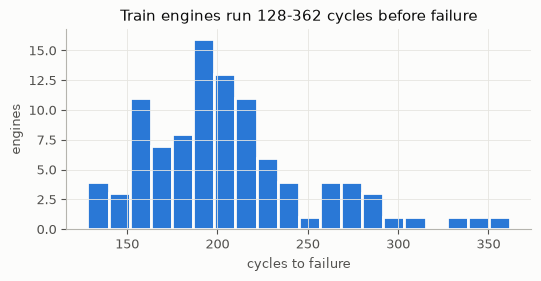

In [2]:
life = train.groupby("engine")["cycle"].max()
print(f"train: {train.shape}, {train.engine.nunique()} engines | test: {test.shape}, {test.engine.nunique()} engines")
print(f"missing values: train {train.isna().sum().sum()}, test {test.isna().sum().sum()}")
print(f"train engine life (cycles): min {life.min()}, median {life.median():.0f}, max {life.max()}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(life, bins=20, color=BLUE, edgecolor="#fcfcfb", linewidth=2)
ax.set(title="Train engines run 128-362 cycles before failure", xlabel="cycles to failure", ylabel="engines")
plt.show()

## 2. Near-constant columns

A column that barely moves carries no information about health. We measure each column's
standard deviation (std), number of unique values, and rank correlation (Spearman) with true RUL.
Columns with std below `near_constant_std` in `configs/config.yaml` are dropped.

In [3]:
cols = SETTINGS + SENSORS
summary = pd.DataFrame({
    "mean": train[cols].mean(),
    "std": train[cols].std(),
    "n_unique": train[cols].nunique(),
    "spearman_vs_rul": train[cols].corrwith(train["rul"], method="spearman"),
}).sort_values("std")
summary["drop"] = summary["std"] < cfg["data"]["near_constant_std"]
dropped = summary.index[summary["drop"]].tolist()
kept = [s for s in SENSORS if s not in dropped]
print("dropped:", dropped)
print("kept sensors:", kept)
summary.round(4)

dropped: ['s1', 'setting_3', 's10', 's19', 's18', 's16', 's5', 'setting_2', 's6', 'setting_1']
kept sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


,mean,std,n_unique,spearman_vs_rul,drop
s1,518.6700,0.0000,1,NaN,True
setting_3,100.0000,0.0000,1,NaN,True
s10,1.3000,0.0000,1,NaN,True
s19,100.0000,0.0000,1,NaN,True
s18,2388.0000,0.0000,1,NaN,True
s16,0.0300,0.0000,1,NaN,True
s5,14.6200,0.0000,1,NaN,True
setting_2,0.0000,0.0003,13,-0.0038,True
s6,21.6098,0.0014,2,-0.1281,True
setting_1,-0.0000,0.0022,158,-0.0013,True


## 3. Every sensor over engine life

x-axis = cycles before failure (0 = failure), so all engines line up at the end.
Gray: 20 example engines. Blue: fleet median at each cycles-before-failure.

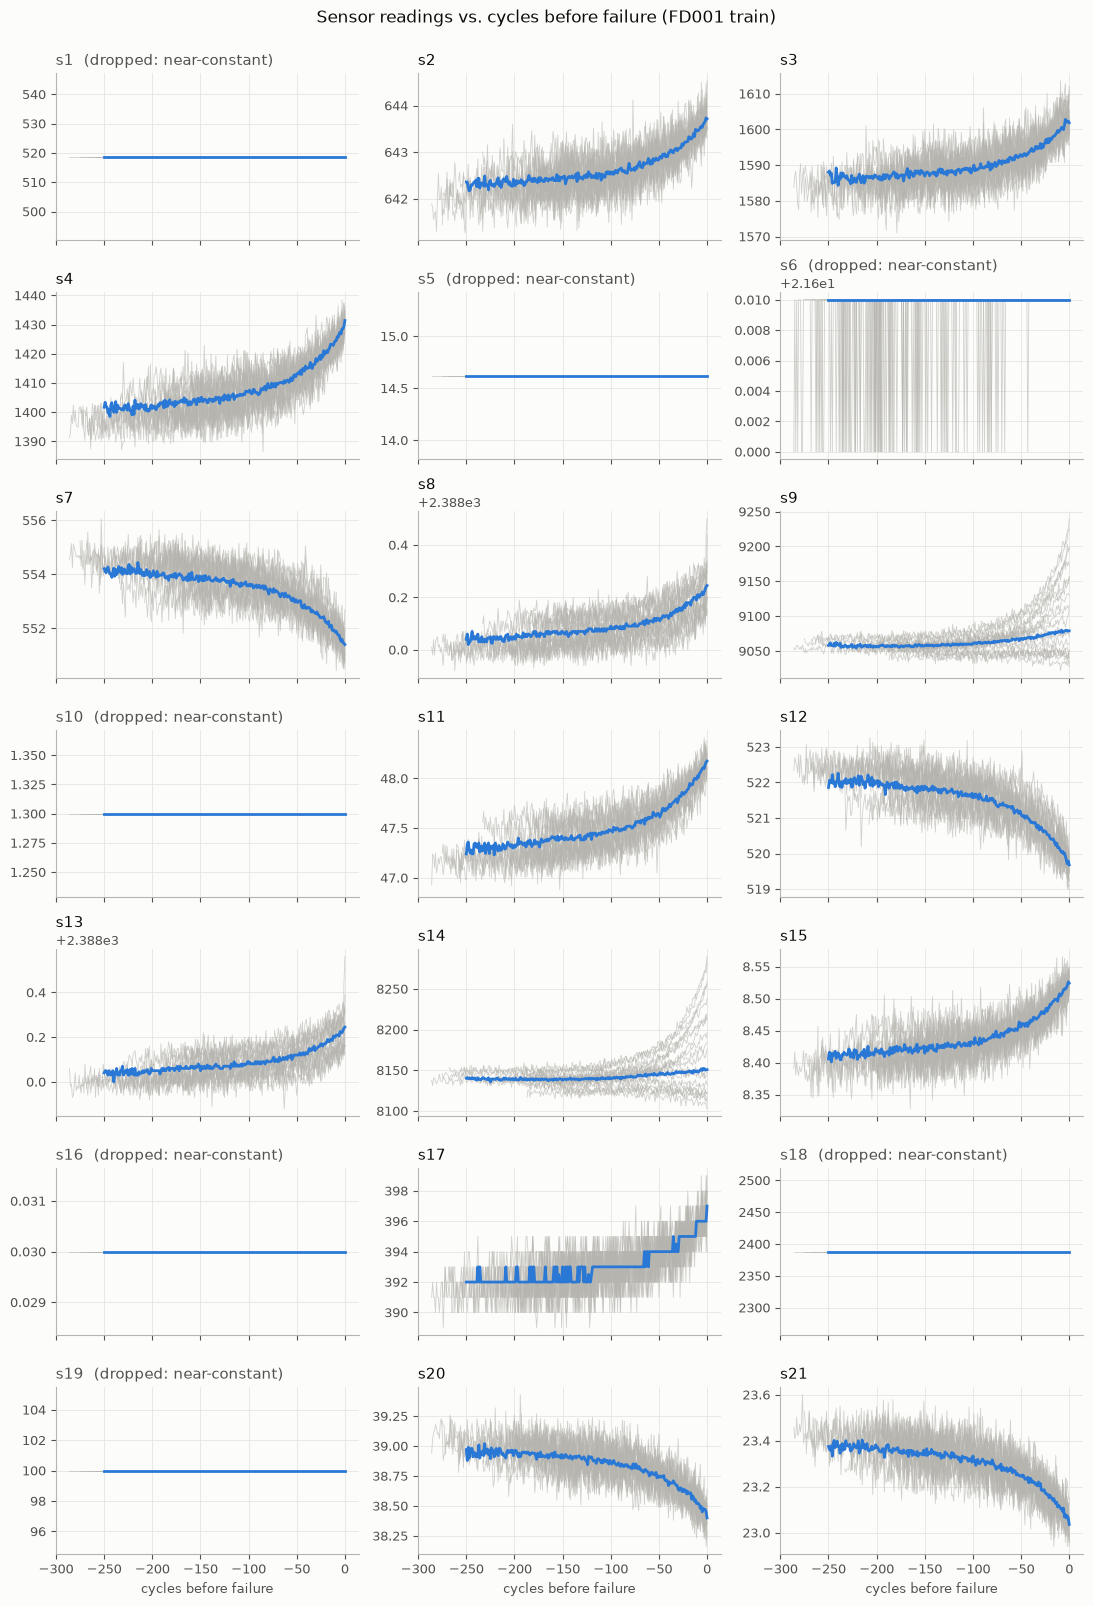

In [4]:
sample = train[train.engine.isin(train.engine.unique()[:20])]
median = train[train.rul <= 250].groupby("rul")[SENSORS].median()

fig, axes = plt.subplots(7, 3, figsize=(11, 16), sharex=True)
for ax, s in zip(axes.flat, SENSORS):
    for _, g in sample.groupby("engine"):
        ax.plot(-g.rul, g[s], color=GRAY, linewidth=0.6, alpha=0.6)
    ax.plot(-median.index, median[s], color=BLUE, linewidth=2)
    tag = "  (dropped: near-constant)" if s in dropped else ""
    ax.set_title(f"{s}{tag}", loc="left", color=INK2 if tag else INK)
for ax in axes[-1]:
    ax.set_xlabel("cycles before failure")
fig.suptitle("Sensor readings vs. cycles before failure (FD001 train)", y=1.0, fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_sensor_trajectories.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Which sensors trend toward failure?

Three measures per kept sensor:
- **spearman_vs_rul**: rank correlation with true RUL over all rows. Negative = rises toward failure.
- **shift_z**: per engine, (mean of last 10 cycles − mean of first 30 cycles) ÷ std of the first 30 cycles
  across the fleet. "How many noise-widths does the sensor move between healthy and failing?" Median over engines.
- **same_direction**: share of engines whose shift has the same sign as the fleet median. Near 1.0 = consistent signal.

In [5]:
early = train[train.cycle <= 30]
late = train[train.rul < 10]
noise = early[kept].std()
shift = (late.groupby("engine")[kept].mean() - early.groupby("engine")[kept].mean()) / noise

trend = pd.DataFrame({
    "spearman_vs_rul": summary.loc[kept, "spearman_vs_rul"],
    "direction_near_failure": np.where(summary.loc[kept, "spearman_vs_rul"] < 0, "up", "down"),
    "shift_z": shift.median(),
    "same_direction": (np.sign(shift) == np.sign(shift.median())).mean(),
}).sort_values("spearman_vs_rul", key=abs, ascending=False)
trend.round(3)

,spearman_vs_rul,direction_near_failure,shift_z,same_direction
s11,-0.718,up,4.107,1.00
s4,-0.702,up,4.157,1.00
s12,0.693,down,-3.853,1.00
s7,0.679,down,-3.669,1.00
s15,-0.666,up,3.650,1.00
s21,0.657,down,-3.383,1.00
s20,0.653,down,-3.582,1.00
s17,-0.629,up,3.297,1.00
s2,-0.629,up,3.165,1.00
s3,-0.606,up,3.088,1.00


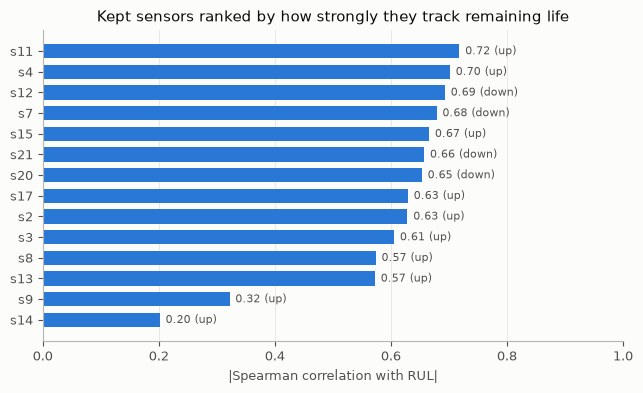

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
t = trend.iloc[::-1]
ax.barh(t.index, t.spearman_vs_rul.abs(), color=BLUE, height=0.7)
for y, (v, d) in enumerate(zip(t.spearman_vs_rul.abs(), t.direction_near_failure)):
    ax.text(v + 0.01, y, f"{v:.2f} ({d})", va="center", color=INK2, fontsize=8)
ax.set(xlim=(0, 1), xlabel="|Spearman correlation with RUL|",
       title="Kept sensors ranked by how strongly they track remaining life")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_trend_strength.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Redundancy between kept sensors

Highly correlated pairs carry overlapping information (matters for explanations in Phase 4).

In [7]:
corr = train[kept].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(3)

s9   s14    0.963
s11  s12   -0.847
s4   s11    0.830
s8   s13    0.826
s7   s11   -0.823
s4   s12   -0.816
s7   s12    0.813
dtype: float64

## 6. Test set and the RUL cap

In [8]:
print(f"train rows with RUL > cap ({CAP}): {(train.rul > CAP).mean():.1%}")
print(f"test engines: true RUL at last row min {true_rul.min()}, median {true_rul.median():.0f}, max {true_rul.max()}")
print(f"test engines with true RUL > cap: {(true_rul > CAP).sum()} of {len(true_rul)}")
print(f"test engines observed for < 50 cycles: {(test.groupby('engine').cycle.max() < 50).sum()}")

train rows with RUL > cap (125): 38.9%
test engines: true RUL at last row min 7, median 86, max 145
test engines with true RUL > cap: 11 of 100
test engines observed for < 50 cycles: 7


## 7. Conclusions

### Dropped columns (10): 7 sensors + 3 settings

| Column | Why dropped |
|---|---|
| s1, s5, s10, s16, s18, s19 | Exactly one value across all 20,631 train rows. Zero information. |
| s6 | Only 2 distinct values that flicker at random; Spearman with RUL −0.13. Measurement resolution, not wear. |
| setting_1, setting_2 | Tiny noise around 0 (std 0.0022 and 0.0003), Spearman ≈ 0. FD001 has one operating condition, so settings say nothing about health. |
| setting_3 | Constant (100). |

The cutoff (`near_constant_std: 0.01`) sits in a clear gap: the largest dropped std is 0.0022, the smallest kept is 0.0375.
The drop list is learned on **train** and applied unchanged to test — never re-derived on test data.

### Sensors that trend toward failure (14 kept)

- **12 strong, consistent sensors:** s11, s4, s12, s7, s15, s21, s20, s17, s2, s3, s8, s13.
  |Spearman| 0.57–0.72; **all 100 engines** move the same direction; they shift 2.9–4.2 noise-widths between healthy and failing.
  - Rise toward failure: s2, s3, s4, s8, s11, s13, s15, s17.
  - Fall toward failure: s7, s12, s20, s21.
- **2 weak, engine-dependent sensors:** s9, s14 (|Spearman| 0.32 and 0.20; same direction in only 71% and 58% of engines).
  The plot shows them fanning out near failure: some engines rise sharply, others drift down.
  **Kept for now** — they are not near-constant, and per-engine features may make them useful. Phase 3 decides with validation, not by eye.
- **Shape:** sensors are flat for most of life and bend in the last ~100–150 cycles. This supports the RUL cap of 125.

### Redundancy

s9–s14 correlate at 0.96 (nearly the same signal). s4, s7, s11, s12 form a cluster (|r| 0.81–0.85); s8–s13 at 0.83.
For Phase 4: SHAP may split credit between "twin" sensors, so explanations may need to talk about sensor groups.

### Data limits

1. **Simulation, not field data.** NASA turbofan data is a stand-in for rotating equipment. Real sensors have gaps, drift, recalibrations and maintenance events; none of that is here.
2. **Small sample.** 100 run-to-failure engines; a 5-fold engine split leaves ~20 engines per validation fold, so scores will be noisy. Report spread across folds, not just the mean.
3. **One operating condition, one fault mode** (HPC degradation, per the NASA readme). Results do not automatically carry over to other conditions or faults (FD002–FD004).
4. **"Failure" is a simulation threshold** — the end of each train series — not a physical breakdown. What a failure costs is our assumption (`configs/costs.yaml`).
5. **Test engines stop early.** True RUL at the last test row ranges 7–145 cycles. 11 of 100 have true RUL above the 125 cap, so a capped model will under-predict them by design. 7 test engines have fewer than 50 cycles of history — short input for rolling windows.
6. **Coarse sensors.** s17 has only 13 distinct values (integer steps); s8 and s13 about 55. Rolling means will smooth this.
7. **Label cap side effect.** 38.9% of train rows have true RUL above 125 and all share the label 125.
8. **Sensor names come from documentation, not the data.** The data files hold sensor indices only. Names and units (used from Phase 4) come from NASA's C-MAPSS paper, Table 2, assuming the columns follow the table's order — supported by the data (s1 = 518.67 °R ≈ 59 °F sea-level inlet temperature; s5 = 14.62 psia sea-level pressure). We use the names as labels and avoid physical claims we cannot check.
